# Phase 06 — Power, MDE, Sample Size and Business Impact

## Objective

Plan hypothetical future A/B experiments using statistical power, minimum detectable effect (MDE), sample-size calculations, and business-impact scenarios.

## Approved Experiment Settings

- Statistical test: Two-sided two-proportion z-test
- Significance level (alpha): 0.05
- Target statistical power: 80%
- Planned allocation: 50/50
- Primary minimum practical effect (MPE): +1 percentage point
- Unit of analysis: Unique user

## Scientific Safeguards

- Power and sample-size calculations are for planning and sensitivity analysis.
- Do not calculate observed/post-hoc power using the observed treatment effect.
- The historical control conversion rate may be used as a future-planning baseline, not as a verified pre-experiment assumption.
- The original group assignments remain provisional because an independent original assignment log is unavailable.
- Business-impact scenarios must be labeled hypothetical.
- Do not interpret statistical non-significance as proof of equivalence.

## Analysis Roadmap

1. Define planning inputs.
2. Calculate prospective sample size.
3. Calculate fixed-sample MDE.
4. Perform planning sensitivity analysis.
5. Estimate hypothetical incremental conversions.
6. Document business implications and limitations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

print("Phase 06 statistical libraries imported successfully.")

Phase 06 statistical libraries imported successfully.


In [2]:
## Step 06.09 — Approved Statistical Planning Parameters

alpha = 0.05

# Approved prospective planning power target
target_power = 0.80

# Approved minimum practical effect: +1 percentage point
primary_mpe = 0.01

# Treatment-to-control allocation ratio (50/50)
allocation_ratio = 1.0

print("Alpha:", alpha)
print("Target power:", f"{target_power:.0%}")
print("Primary MPE:", f"{primary_mpe * 100:.2f} percentage point")
print("Treatment/control allocation ratio:", allocation_ratio)

Alpha: 0.05
Target power: 80%
Primary MPE: 1.00 percentage point
Treatment/control allocation ratio: 1.0


In [3]:
# Step 06.10 — Historical Baseline for Future Planning

# Verified Phase 05 control-group counts
historical_control_users = 145_294
historical_control_conversions = 17_496

# Historical control conversion probability
baseline_rate = (
    historical_control_conversions / historical_control_users
)

# Hypothetical treatment rate for the approved +1 pp MPE
planning_treatment_rate = baseline_rate + primary_mpe

print(f"Historical baseline conversion rate: {baseline_rate:.6%}")
print(f"Hypothetical treatment conversion rate: {planning_treatment_rate:.6%}")
print(f"Planned absolute improvement: {(planning_treatment_rate - baseline_rate) * 100:.2f} percentage point")

Historical baseline conversion rate: 12.041791%
Hypothetical treatment conversion rate: 13.041791%
Planned absolute improvement: 1.00 percentage point


In [4]:
# Step 06.11 — Standardized Effect Size for Future Planning

planning_effect_size = proportion_effectsize(
    planning_treatment_rate,
    baseline_rate
)

print(
    f"Standardized planning effect size (Cohen h): "
    f"{planning_effect_size:.6f}"
)

print(
    f"Absolute planning improvement: "
    f"{primary_mpe * 100:.2f} percentage point"
)

Standardized planning effect size (Cohen h): 0.030200
Absolute planning improvement: 1.00 percentage point


In [5]:
# Step 06.12 — Prospective Sample Size Calculation

# Initialize the two-independent-proportions power model
power_model = NormalIndPower()

# Calculate required control-group sample size
required_n_control = power_model.solve_power(
    effect_size=planning_effect_size,
    alpha=alpha,
    power=target_power,
    ratio=allocation_ratio,
    alternative="two-sided"
)

# Round up because sample sizes must be whole users
required_users_per_group = int(np.ceil(required_n_control))
required_total_users = required_users_per_group * 2

print(
    f"Unrounded required users per group: "
    f"{required_n_control:.2f}"
)

print(
    f"Required users per group: "
    f"{required_users_per_group:,}"
)

print(
    f"Total required users: "
    f"{required_total_users:,}"
)

Unrounded required users per group: 17212.23
Required users per group: 17,213
Total required users: 34,426


In [6]:
# Step 06.13 — Verify Prospective Planning Power

verified_planning_power = power_model.power(
    effect_size=planning_effect_size,
    nobs1=required_users_per_group,
    alpha=alpha,
    ratio=allocation_ratio,
    alternative="two-sided"
)

print(f"Target planning power: {target_power:.4%}")
print(f"Calculated planning power: {verified_planning_power:.4%}")
print(f"Meets target power: {verified_planning_power >= target_power}")

Target planning power: 80.0000%
Calculated planning power: 80.0018%
Meets target power: True


In [7]:
# Step 06.15 — Fixed-Sample MDE Planning Inputs

# Verified sample sizes from Phase 04
fixed_n_control = 145_294
fixed_n_treatment = 145_290

# Actual treatment-to-control allocation ratio
fixed_allocation_ratio = (
    fixed_n_treatment / fixed_n_control
)

fixed_total_users = fixed_n_control + fixed_n_treatment

print(f"Fixed control users: {fixed_n_control:,}")
print(f"Fixed treatment users: {fixed_n_treatment:,}")
print(f"Fixed total users: {fixed_total_users:,}")
print(f"Actual allocation ratio: {fixed_allocation_ratio:.8f}")

Fixed control users: 145,294
Fixed treatment users: 145,290
Fixed total users: 290,584
Actual allocation ratio: 0.99997247


In [8]:
# Step 06.16 — Standardized Fixed-Sample MDE

fixed_sample_effect_size = power_model.solve_power(
    effect_size=None,
    nobs1=fixed_n_control,
    alpha=alpha,
    power=target_power,
    ratio=fixed_allocation_ratio,
    alternative="two-sided"
)

print(
    f"Standardized fixed-sample MDE (Cohen h): "
    f"{fixed_sample_effect_size:.6f}"
)
print(f"Target planning power: {target_power:.0%}")
print(f"Fixed total users: {fixed_total_users:,}")

Standardized fixed-sample MDE (Cohen h): 0.010394
Target planning power: 80%
Fixed total users: 290,584


In [9]:
# Step 06.17 — Convert Standardized MDE to Conversion Rates

# Invert Cohen's h transformation for a positive improvement
fixed_mde_treatment_rate = np.sin(
    np.arcsin(np.sqrt(baseline_rate))
    + fixed_sample_effect_size / 2
) ** 2

# Absolute MDE as a probability difference
fixed_mde_absolute = fixed_mde_treatment_rate - baseline_rate

# Absolute MDE in percentage points
fixed_mde_pp = fixed_mde_absolute * 100

# Relative MDE compared with historical baseline
fixed_mde_relative_pct = (
    fixed_mde_absolute / baseline_rate
) * 100

print(f"Historical baseline: {baseline_rate:.6%}")
print(
    f"Hypothetical treatment rate at MDE: "
    f"{fixed_mde_treatment_rate:.6%}"
)
print(f"Absolute MDE: {fixed_mde_pp:.4f} percentage points")
print(f"Relative MDE: {fixed_mde_relative_pct:.4f}%")

Historical baseline: 12.041791%
Hypothetical treatment rate at MDE: 12.382123%
Absolute MDE: 0.3403 percentage points
Relative MDE: 2.8263%


In [10]:
# Step 06.20 — Sample Size Sensitivity by Target Effect

# Hypothetical absolute improvements
effect_scenarios = [0.005, primary_mpe, 0.015]

sample_size_results = []

for effect in effect_scenarios:
    hypothetical_treatment_rate = baseline_rate + effect

    standardized_effect = proportion_effectsize(
        hypothetical_treatment_rate,
        baseline_rate
    )

    required_n = power_model.solve_power(
        effect_size=standardized_effect,
        alpha=alpha,
        power=target_power,
        ratio=allocation_ratio,
        alternative="two-sided"
    )

    users_per_group = int(np.ceil(required_n))

    sample_size_results.append({
        "Target Improvement (pp)": round(effect * 100, 2),
        "Users per Group": users_per_group,
        "Total Users": users_per_group * 2
    })

sensitivity_df = pd.DataFrame(sample_size_results)

print("SAMPLE SIZE SENSITIVITY ANALYSIS")
print(sensitivity_df.to_string(index=False))

SAMPLE SIZE SENSITIVITY ANALYSIS
 Target Improvement (pp)  Users per Group  Total Users
                     0.5            67688       135376
                     1.0            17213        34426
                     1.5             7777        15554


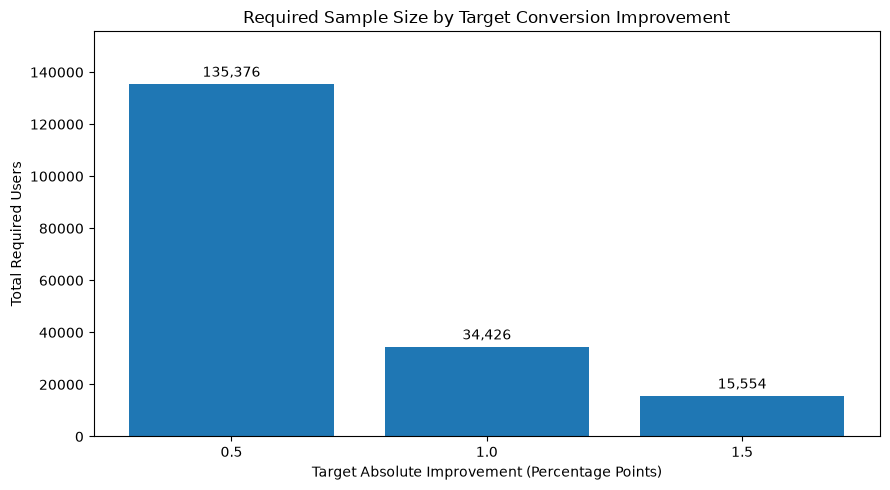

In [11]:
# Step 06.21 — Sample Size Sensitivity Visualization

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    sensitivity_df["Target Improvement (pp)"].astype(str),
    sensitivity_df["Total Users"]
)

ax.set_title(
    "Required Sample Size by Target Conversion Improvement"
)
ax.set_xlabel("Target Absolute Improvement (Percentage Points)")
ax.set_ylabel("Total Required Users")

ax.bar_label(
    bars,
    labels=[
        f"{value:,}"
        for value in sensitivity_df["Total Users"]
    ],
    padding=3
)

ax.set_ylim(
    0,
    sensitivity_df["Total Users"].max() * 1.15
)

plt.tight_layout()
plt.show()

In [12]:
# Step 06.22 — Sample Size Sensitivity by Power Target

power_scenarios = [target_power, 0.90]

power_results = []

for scenario_power in power_scenarios:
    required_n = power_model.solve_power(
        effect_size=planning_effect_size,
        alpha=alpha,
        power=scenario_power,
        ratio=allocation_ratio,
        alternative="two-sided"
    )

    users_per_group = int(np.ceil(required_n))

    power_results.append({
        "Target Power": f"{scenario_power:.0%}",
        "Users per Group": users_per_group,
        "Total Users": users_per_group * 2
    })

power_sensitivity_df = pd.DataFrame(power_results)

print("POWER TARGET SENSITIVITY ANALYSIS")
print(power_sensitivity_df.to_string(index=False))

POWER TARGET SENSITIVITY ANALYSIS
Target Power  Users per Group  Total Users
         80%            17213        34426
         90%            23043        46086


In [13]:
# Step 06.23 — Baseline Conversion Rate Sensitivity

# Hypothetical future-planning baseline scenarios
baseline_scenarios = [0.08, baseline_rate, 0.20]

baseline_results = []

for scenario_baseline in baseline_scenarios:
    scenario_treatment = scenario_baseline + primary_mpe

    scenario_effect_size = proportion_effectsize(
        scenario_treatment,
        scenario_baseline
    )

    required_n = power_model.solve_power(
        effect_size=scenario_effect_size,
        alpha=alpha,
        power=target_power,
        ratio=allocation_ratio,
        alternative="two-sided"
    )

    users_per_group = int(np.ceil(required_n))

    baseline_results.append({
        "Baseline Rate (%)": round(scenario_baseline * 100, 4),
        "Treatment Rate (%)": round(scenario_treatment * 100, 4),
        "Users per Group": users_per_group,
        "Total Users": users_per_group * 2
    })

baseline_sensitivity_df = pd.DataFrame(baseline_results)

print("BASELINE CONVERSION RATE SENSITIVITY")
print(baseline_sensitivity_df.to_string(index=False))

BASELINE CONVERSION RATE SENSITIVITY
 Baseline Rate (%)  Treatment Rate (%)  Users per Group  Total Users
            8.0000              9.0000            12199        24398
           12.0418             13.0418            17213        34426
           20.0000             21.0000            25580        51160


In [14]:
# Step 06.25 — Hypothetical Incremental Conversion Scenarios

# Standardized illustrative traffic volume (not actual company traffic)
illustrative_users = 100_000

# Hypothetical absolute conversion-rate changes
impact_scenarios = [-0.005, 0.005, primary_mpe]

impact_results = []

for change in impact_scenarios:
    incremental_conversions = illustrative_users * change

    impact_results.append({
        "Conversion Change (pp)": round(change * 100, 2),
        "Eligible Users": illustrative_users,
        "Incremental Conversions": int(incremental_conversions)
    })

business_impact_df = pd.DataFrame(impact_results)

print("HYPOTHETICAL BUSINESS IMPACT SCENARIOS")
print(business_impact_df.to_string(index=False))

HYPOTHETICAL BUSINESS IMPACT SCENARIOS
 Conversion Change (pp)  Eligible Users  Incremental Conversions
                   -0.5          100000                     -500
                    0.5          100000                      500
                    1.0          100000                     1000


In [15]:
# Step 06.25 — Hypothetical Incremental Conversion Scenarios

# Standardized illustrative traffic volume (not actual company traffic)
illustrative_users = 100_000

# Hypothetical absolute conversion-rate changes
impact_scenarios = [-0.005, 0.005, primary_mpe]

impact_results = []

for change in impact_scenarios:
    incremental_conversions = illustrative_users * change

    impact_results.append({
        "Conversion Change (pp)": round(change * 100, 2),
        "Eligible Users": illustrative_users,
        "Incremental Conversions": int(incremental_conversions)
    })

business_impact_df = pd.DataFrame(impact_results)

print("HYPOTHETICAL BUSINESS IMPACT SCENARIOS")
print(business_impact_df.to_string(index=False))

HYPOTHETICAL BUSINESS IMPACT SCENARIOS
 Conversion Change (pp)  Eligible Users  Incremental Conversions
                   -0.5          100000                     -500
                    0.5          100000                      500
                    1.0          100000                     1000


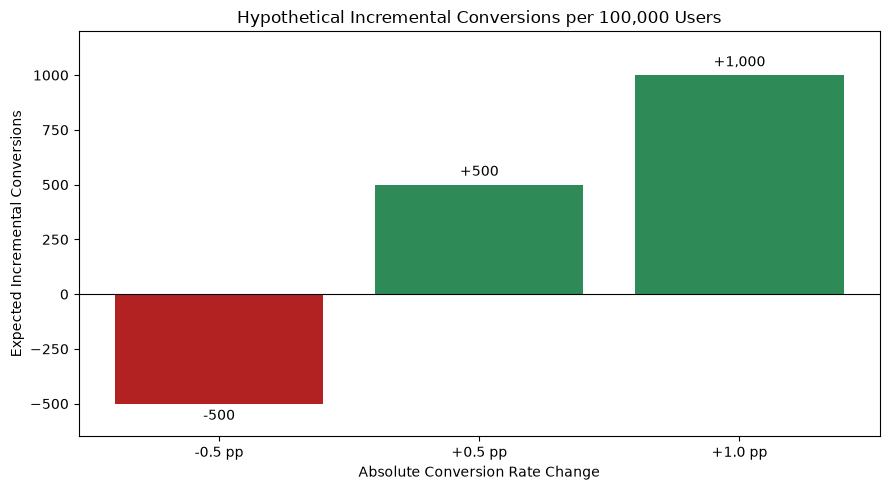

In [16]:
# Step 06.26 — Hypothetical Business Impact Visualization

fig, ax = plt.subplots(figsize=(9, 5))

changes = business_impact_df["Conversion Change (pp)"]
conversions = business_impact_df["Incremental Conversions"]

labels = [f"{value:+.1f} pp" for value in changes]

colors = [
    "firebrick" if value < 0 else "seagreen"
    for value in conversions
]

bars = ax.bar(labels, conversions, color=colors)

ax.axhline(0, color="black", linewidth=0.8)

ax.bar_label(
    bars,
    labels=[f"{value:+,}" for value in conversions],
    padding=4
)

ax.set_title(
    "Hypothetical Incremental Conversions per 100,000 Users"
)
ax.set_xlabel("Absolute Conversion Rate Change")
ax.set_ylabel("Expected Incremental Conversions")

ax.set_ylim(-650, 1200)

plt.tight_layout()
plt.show()

In [17]:
# Step 06.28 — Financial Impact Framework

# Financial inputs are unavailable in the dataset.
# None means unknown, NOT zero.

revenue_per_conversion = None
contribution_profit_per_conversion = None
incremental_costs = None

def calculate_financial_impact(
    incremental_conversions,
    revenue_per_conversion=None,
    contribution_profit_per_conversion=None,
    incremental_costs=None
):
    incremental_revenue = (
        incremental_conversions * revenue_per_conversion
        if revenue_per_conversion is not None
        else None
    )

    incremental_contribution_profit = (
        incremental_conversions * contribution_profit_per_conversion
        if contribution_profit_per_conversion is not None
        else None
    )

    net_incremental_benefit = (
        incremental_contribution_profit - incremental_costs
        if incremental_contribution_profit is not None
        and incremental_costs is not None
        else None
    )

    return {
        "Incremental Revenue": incremental_revenue,
        "Incremental Contribution Profit": incremental_contribution_profit,
        "Net Incremental Benefit": net_incremental_benefit
    }

financial_impact = calculate_financial_impact(
    incremental_conversions=1000,
    revenue_per_conversion=revenue_per_conversion,
    contribution_profit_per_conversion=contribution_profit_per_conversion,
    incremental_costs=incremental_costs
)

print("FINANCIAL IMPACT FRAMEWORK")
for metric, value in financial_impact.items():
    print(f"{metric}: {value}")

FINANCIAL IMPACT FRAMEWORK
Incremental Revenue: None
Incremental Contribution Profit: None
Net Incremental Benefit: None


## Business Interpretation and Limitations

### 1. Prospective Sample-Size Planning

Using the historical control conversion rate of approximately 12.04% as a planning baseline, a hypothetical +1 percentage-point absolute improvement requires approximately **17,213 users per group (34,426 total)** under the following assumptions:

- Two-sided two-proportion z-test
- Significance level: 0.05
- Target statistical power: 80%
- Equal allocation between control and treatment

The baseline was obtained from the analyzed dataset and was **not a pre-experiment locked planning baseline**.

### 2. Minimum Detectable Effect (MDE)

At the analyzed sample sizes, approximately 145,294 control users and 145,290 treatment users, the prospective 80%-power MDE is approximately **+0.3403 percentage points**, using the historical control rate as the reference baseline.

This is a planning sensitivity calculation, **not an observed treatment effect or a post-hoc observed-power calculation**.

### 3. Sensitivity Analysis

Sample-size requirements change when the assumed effect size, statistical power, or baseline conversion rate changes.

The approved primary planning assumptions remain:

- Minimum Practically Important Effect (MPE): +1 percentage point
- Target power: 80%
- Significance level: 0.05

Alternative scenarios are sensitivity analyses, not changes to the approved experiment design.

### 4. Hypothetical Conversion Impact

For a standardized illustrative population of 100,000 eligible users:

- A -0.5 percentage-point change corresponds to 500 fewer expected conversions.
- A +0.5 percentage-point change corresponds to 500 additional expected conversions.
- A +1.0 percentage-point change corresponds to 1,000 additional expected conversions.

These are **hypothetical scenarios**, not measured causal effects or verified company traffic forecasts.

### 5. Financial Impact

Incremental revenue, incremental contribution profit, and net incremental benefit cannot be calculated because verified financial inputs are unavailable.

Missing financial information must not be interpreted as zero financial impact.

### 6. Experiment Interpretation and Limitations

The Phase 05 primary analysis found a treatment-minus-control conversion-rate difference of approximately **-0.1587 percentage points**, with a 95% confidence interval of approximately **[-0.3947, +0.0773] percentage points** and a two-sided p-value of approximately **0.1876**.

The result was not statistically significant at the 0.05 level. This does **not** establish equivalence or prove that the redesign has no effect.

The assignment data remain provisional because the earliest observed user record was used without an independently verified original randomization log. This limits causal certainty.

The planning and business-impact scenarios in this notebook do not change the Phase 05 statistical result or establish that the redesigned page produced additional conversions.

### 7. Product Decision Implication

The current evidence does not justify claiming a statistically demonstrated conversion improvement from the redesign.

The Product Manager should avoid presenting hypothetical planning scenarios as realized business gains and should account for the assignment-data limitations when making a rollout decision.